# 02 · Encoding: one-hot + padding

**Workflow step: Step 2 (a) of Figure 1 in the proposal** ("Workflow of the proposed approach and the evaluation").
Step 1 (notebook 01) gave one row per journal entry and the JET flags. For Step 2 every entry must become **one numeric vector of fixed length**, because the detectors of Step 3 (baselines) and Step 4 (proposed approach) — Isolation Forest, LOF, autoencoder — cannot read posting lines directly. Step 2 has two encodings: (a) one-hot + padding, built here, and (b) sentence embeddings (notebook 04), which replace only the account / debit-credit block of this encoding (D16).

## Purpose of this notebook
An entry has 2 to 4 posting lines. This notebook turns each entry into a vector (one-hot categories per line slot, padded to 4 slots), and on the way it **engineers the features and justifies every choice with the data**:

1. **Load** the posting lines and the meta table — section 1.
2. **Line level or entry level?** Which fields are encoded once per entry (D13) — section 2.
3. **Line order** inside the padding, so that the vector depends on the content only (D9) — section 3.
4. **Categorical fields** one-hot per slot with a PAD category — section 4.
5. **Numeric fields**: look at their distributions, choose the transformation per field, build the new time features (D4, D10, D11) — section 5.
6. **Redundancy without labels**: which candidate features are switched off because another field already determines them (D4, D13) — section 6.
7. **Descriptive views with labels, FY2023 only** (D6): item text, delay, time of day, weekday (D1, D4, D11) — section 7.
8. **Build the matrix** with all candidate features, check it, and check identical vectors (D15) — section 8.
9. **Save once, switch feature groups per run** (main setting = 131 columns; ablations) — section 9.

Rule used throughout: decisions to switch a feature on or off come from **label-free** checks (redundancy, dimension, duplicates). Views with labels are descriptive and use FY2023 only, so no label of the reporting year FY2024 enters a design choice (D6).

<div dir="rtl">

## هدف این notebook (فارسی)

**مرحله در workflow: ‏Step 2 (a) در Figure 1 پروپوزال.** در Step 1 (notebook 01) هر سند یک ردیف شد و پرچم‌های JET ساخته شدند. برای Step 2 باید هر سند **یک بردار عددی با طول ثابت** شود، چون detectorهای Step 3 (baselineها) و Step 4 (روش پیشنهادی) — یعنی Isolation Forest، ‏LOF و autoencoder — نمی‌توانند خط‌های ثبت را مستقیم بخوانند. Step 2 دو encoding دارد: (a) ‏one-hot + padding که اینجا ساخته می‌شود، و (b) ‏sentence embedding (notebook 04) که فقط بلوک «حساب و بدهکار/بستانکار» همین encoding را جایگزین می‌کند (D16).

هر سند ۲ تا ۴ خط دارد. این notebook هر سند را به یک بردار تبدیل می‌کند (one-hot برای هر جای خط، padding تا ۴ جای خط) و در همین مسیر **ویژگی‌ها را می‌سازد و هر انتخاب را با داده توجیه می‌کند**:

۱. بارگذاری داده – بخش ۱
۲. چه چیزی سطح خط است و چه چیزی سطح سند (D13) – بخش ۲
۳. ترتیب خط‌ها داخل padding (D9) – بخش ۳
۴. فیلدهای دسته‌ای: one-hot برای هر جای خط با دستهٔ PAD – بخش ۴
۵. فیلدهای عددی: توزیع، انتخاب تبدیل برای هر فیلد، ساخت ویژگی‌های زمانی جدید (D4، D10، D11) – بخش ۵
۶. افزونگی بدون برچسب: کدام ویژگی‌ها خاموش می‌شوند چون فیلد دیگری کاملاً تعیینشان می‌کند (D4، D13) – بخش ۶
۷. نمای توصیفی با برچسب، فقط FY2023 (D6): متن کالا، تأخیر، ساعت، روز هفته (D1، D4، D11) – بخش ۷
۸. ساخت ماتریس با همهٔ ویژگی‌های کاندید، چک‌ها، و بردارهای تکراری (D15) – بخش ۸
۹. یک بار ذخیره، انتخاب گروه ویژگی‌ها در هر اجرا (تنظیم اصلی ۱۳۱ ستون؛ ablationها) – بخش ۹

قاعده: تصمیم روشن/خاموش کردن ویژگی فقط از بررسی‌های **بدون برچسب** می‌آید؛ نماهای برچسب‌دار فقط توصیفی‌اند و فقط روی FY2023.

</div>

## Inputs, outputs and decisions used

**Input:** `data/raw/journal_entries_4203.csv` (never modified; download from Zenodo, doi 10.5281/zenodo.22014653, and put it in `data/raw/`), `data/derived/meta.parquet` (run notebook 01 first).
**Output:** `data/derived/X_onehot.npz` (sparse, rows in `meta.parquet` order) + `data/derived/onehot_features.json` (column names, feature groups, fitted parameters, encoding version, row order); figures in `results/figures/`.

Decisions (Decisions sheet of `Thesis_Execution_Plan.xlsx`); text drafts for the thesis are in `thesis_writing_snippets.md` (W-numbers):

| ID | What | Setting | Section |
|---|---|---|---|
| D13 | entry-level fields | `user` once per entry; `tax_rate`, `n_lines` built but **off** (determined by the booking pattern) | 2, 6 |
| D9 | line order inside the padding | debit first, then account number, then amount (largest first), then CSV position | 3 |
| D10 | scalers | log1p → min-max, fitted per fiscal year (same entries as the detector, D6) | 5 |
| D4 | time features | `lag_days` (continuous) + `weekend` + `nwh`; `promptly` built but **off** (binning of `lag_days`) | 5, 6, 7 |
| D11 | extra time features | `nwh_dist`, hour sin/cos, weekday sin/cos built for ablations only, **off** | 5, 7 |
| D1 | free text `text` | not encoded | 7 |
| D15 | LOF neighbourhood | k above the largest group of identical vectors | 8 |

Main setting = **131 columns** (encoding version v3).

## 1. Load the posting lines and the meta table

**Goal.** Read the two inputs and make sure they describe the same journal entries. `meta.parquet` fixes the row order of every matrix in this project: row *i* of the encoding, of the embeddings and of every score vector is entry *i* of `meta`. If an entry were missing in one of the two tables, labels and scores would be shifted without any error.

In [1]:
# cell_02_01
import sys
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)

RAW_REL = Path("data/raw/journal_entries_4203.csv")


def find_project_root(marker: Path = RAW_REL) -> Path:
    # walk up from the working directory until `marker` exists (same as notebook 01)
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found from {here} upwards: put the CSV in data/raw/")


ROOT = find_project_root()
sys.path.insert(0, str(ROOT))          # makes src/ importable (laptop and Colab)
from src.load import load_lines
from src import encode as fe
from src import figures as fg
from src import detectors as dt

DATA = ROOT / RAW_REL
DERIVED = ROOT / "data" / "derived"
FIG = ROOT / "results" / "figures"
FY1, FY2 = 2023, 2024    # FY1: tuning year and the only year whose labels inform choices (D6); FY2: reporting year
print("project root:", ROOT)

project root: C:\MyWorks\Thesis\Jet


In [2]:
# cell_02_02
lines = load_lines(DATA)                     # src/load.py: dates parsed, adds fy and line_no
meta = pd.read_parquet(DERIVED / "meta.parquet")

print("posting lines:", lines.shape, "| entries:", meta.shape)
assert len(meta) == 102_429 and lines["posting_id"].nunique() == len(meta)
assert set(lines["posting_id"]) == set(meta["posting_id"])        # same entries (the order is set by meta)
fy_lines = lines.groupby("posting_id")["fy"].first()
assert (fy_lines.reindex(meta["posting_id"]).to_numpy() == meta["fy"].to_numpy()).all()   # same fiscal year

posting lines: (256232, 21) | entries: (102429, 11)


**Result.** 256,232 posting lines form 102,429 entries; both tables contain exactly the same entries and agree on the fiscal year. The *set* check does not test the order — the order is fixed later: `build_onehot` places every line in the row of its `posting_id` in `meta`, and section 9 stores that order with the matrix.

## 2. Which fields are per line and which per entry? (D13)

**Goal.** A field that has one value inside every entry is encoded **once per entry**, not once per line slot. Repeating it in 4 slots would count the same fact up to four times in every distance (LOF, autoencoder) and give it more weight than the accounts. The check counts, for each column, the entries in which it takes more than one distinct value.

In [3]:
# cell_02_03
g = lines.groupby("posting_id", sort=False)
check_cols = fe.ENTRY_COLS + ["posting_date", "text", "label", "marking", "gl_account", "cd_flag", "amount"]
# per column: number of entries with more than one distinct value (missing values count as a value)
# 0 = constant inside every entry -> entry-level field
check = pd.Series({c: int((g[c].nunique(dropna=False) > 1).sum()) for c in check_cols},
                  name="entries with >1 distinct value")
check

document_date         0
entered_date          0
user                  0
tax_rate              0
promptly              0
weekend               0
nwh                   0
posting_date          0
text                  0
label                 0
marking               0
gl_account       102429
cd_flag          102429
amount            51373
Name: entries with >1 distinct value, dtype: int64

In [4]:
# cell_02_04
# expected: 0 for all entry-level fields (the same guard runs inside fe.entry_table, so build_onehot
# stops on a ledger where, e.g., one document carries several tax rates)
for c in fe.ENTRY_COLS + ["posting_date", "text", "label", "marking"]:
    assert check[c] == 0, c
assert check["gl_account"] == check["cd_flag"] == len(meta)       # every entry has 2+ accounts and both sides

**Result.** User, dates, tax rate, the three dataset time flags, the text, the label and the marking are constant inside every entry (0 exceptions); accounts and debit/credit vary in every entry. Amounts differ in 51,373 entries: 102,429 − 51,373 = 51,056 is exactly the number of two-line entries, whose debit and credit amounts are equal.

For the user and the dates this also holds in a real ERP system (header fields of the document, SAP table BKPF). The **tax rate** is different: in real ledgers it is a line-item field (SAP BSEG-MWSKZ), and one document can carry several rates — here it is constant only because the generator sets it per transaction (L1). Labels and markings being constant means "one anomalous line marks the whole entry" is not a modelling choice here. (W1)

### Debit / credit sequences as stored in the CSV

**Goal.** Describe how the lines are stored (descriptive only — both years, no choice is made from this table; D6). The *debit/credit sequence* is the D/C letters in CSV order; it is not the *booking pattern* (accounts + sides, section 3), see W2.

In [5]:
# cell_02_05
cd_sequence = g["cd_flag"].agg("".join).rename("cd_sequence")
seq = (pd.DataFrame({"cd_sequence": cd_sequence})
       .join(meta.set_index("posting_id")[["label"]])
       .groupby("cd_sequence")["label"].agg(entries="size", anomalies="sum"))
seq

,entries,anomalies
cd_sequence,,
CCD,60,0
DC,51056,542
DCC,18000,91
DDC,33312,217
DDDC,1,0


**Result.** Five sequences: DC 51,056 entries, DDC 33,312, DCC 18,000, CCD 60, DDDC 1. CCD and DCC have the same structure (one debit, two credits) and differ only in how they are stored — the first hint that the stored order is not a content order (section 3). Differences in the anomaly rate between sequences come from where the generator injected the anomaly types and are not interpreted.

### The only four-line entry

**Goal.** Show the entry that alone fills the fourth line slot; the one-hot encoding will make it isolated, so its rank is checked later (notebook 03).

In [6]:
# cell_02_06
four = meta.loc[meta["n_lines"] == 4, "posting_id"].tolist()
print(four)
cols = ["posting_id", "document_date", "user", "gl_account", "gl_account_name", "cd_flag", "amount", "text", "ref_id", "label"]
show = lines.loc[lines["posting_id"].isin(four), cols]
print("account 2020 used in", int((lines["gl_account"] == 2020).sum()), "line(s); account 1700 in",
      int((lines["gl_account"] == 1700).sum()))
show

['p_2']
account 2020 used in 1 line(s); account 1700 in 2


,posting_id,document_date,user,gl_account,gl_account_name,cd_flag,amount,text,ref_id,label
256224,p_2,2024-02-06,Alice,1700,Other liabilities,D,1490.90,Invoice utilities December 2023,p_1,0
256225,p_2,2024-02-06,Alice,2020,Prior-period expenses,D,63.36,Invoice utilities December 2023,p_1,0
256226,p_2,2024-02-06,Alice,1576,"Deductible input tax, 19%",D,295.31,Invoice utilities December 2023,p_1,0
256227,p_2,2024-02-06,Alice,1600,Trade payables,C,1849.57,Invoice utilities December 2023,p_1,0


**Result.** `p_2` (Feb 2024, label normal) settles a liability from the previous period: it debits *Other liabilities* (1700) and *Prior-period expenses* (2020) with 19 % input tax against *Trade payables*. It is rare for two reasons: it alone fills slot 4 (an effect of the encoding), and account 2020 occurs on this line only (rare content; prior-period items are of interest for cut-off testing). FY2023 has no four-line entry, so the hyperparameter choice on FY2023 cannot see this effect (W5).

## 3. Line order inside the padding (D9)

**Goal.** Each slot must mean the same thing in every entry. The lines are sorted before padding: **debit first, then account number, then amount (largest first), then the CSV position** (`fe.sort_lines`). The checks below ask (a) how many entries the sorting changes, (b) whether the stored order is *inconsistent* — the only case in which entries with the same content would get different vectors without sorting — and (c) what the sorting costs.

In [7]:
# cell_02_07
sorted_lines = fe.sort_lines(lines)                 # adds csv_pos (stored position) and slot (D9 position)
changed = fe.order_changes(sorted_lines)
print(f"entries whose CSV order differs from the D9 order: {changed.sum():,} of {len(changed):,} ({changed.mean():.1%})")
(pd.DataFrame({"changed": changed}).join(cd_sequence)
   .groupby("cd_sequence")["changed"].agg(entries="size", changed="sum"))

entries whose CSV order differs from the D9 order: 51,253 of 102,429 (50.0%)


,entries,changed
cd_sequence,,
CCD,60,60
DC,51056,0
DCC,18000,18000
DDC,33312,33192
DDDC,1,1


In [8]:
# cell_02_08
# (b) is the stored order consistent within each booking pattern (same accounts and sides)?
csv_order = lines.groupby("posting_id", sort=False).apply(lambda x: tuple(zip(x["cd_flag"], x["gl_account"])))
content = csv_order.apply(lambda t: tuple(sorted(t)))         # order-free key of the content
orders_per_pattern = pd.DataFrame({"content": content, "csv": csv_order}).groupby("content")["csv"].nunique()
print(f"booking patterns: {len(orders_per_pattern)}, stored in more than one order: {(orders_per_pattern > 1).sum()}")
first_slot = sorted_lines[sorted_lines["csv_pos"] == 0]["cd_flag"].value_counts()
print("side of the first stored line:", first_slot.to_dict())

booking patterns: 29, stored in more than one order: 0
side of the first stored line: {'D': 102369, 'C': 60}


In [9]:
# cell_02_09
# (c) example for the thesis: a purchase (a_1) and its reversal (r_1), stored order vs D9 order
ex = ["a_1", "r_1"]
cols = ["posting_id", "csv_pos", "slot", "cd_flag", "gl_account", "gl_account_name", "amount"]
pair = sorted_lines.loc[sorted_lines["posting_id"].isin(ex), cols].sort_values(["posting_id", "csv_pos"])
display(pair)


def side_account_block(df, pos_col):
    # one-hot of (slot, side) and (slot, account) for the given order -> distance in the account + side block
    keys = [f"{p}_{c}" for p, c in zip(df[pos_col], df["cd_flag"])] + [f"{p}_{a}" for p, a in zip(df[pos_col], df["gl_account"])]
    return set(keys)


for pos in ["csv_pos", "slot"]:
    a = side_account_block(pair[pair["posting_id"] == "a_1"], pos)
    r = side_account_block(pair[pair["posting_id"] == "r_1"], pos)
    print(f"{'stored order' if pos == 'csv_pos' else 'D9 order':13s}: distance in the account + side block = {np.sqrt(len(a ^ r)):.2f}")

,posting_id,csv_pos,slot,cd_flag,gl_account,gl_account_name,amount
0,a_1,0,1,D,3400,"Cost of merchandise, 19% input tax",112.42
1,a_1,1,0,D,1576,"Deductible input tax, 19%",21.36
2,a_1,2,2,C,1600,Trade payables,133.78
127709,r_1,0,2,C,3400,"Cost of merchandise, 19% input tax",1096.20
127710,r_1,1,1,C,1576,"Deductible input tax, 19%",208.28
127711,r_1,2,0,D,1600,Trade payables,1304.48


stored order : distance in the account + side block = 2.45
D9 order     : distance in the account + side block = 2.83


In [10]:
# cell_02_10
# tie-break: two lines on the same side and the same account inside one entry?
dup = sorted_lines.groupby(["posting_id", "cd_flag", "gl_account"]).size()
n_tie = dup[dup > 1].index.get_level_values("posting_id").nunique()
print("entries with two lines on the same side and account (amount tie-break needed):", n_tie)

entries with two lines on the same side and account (amount tie-break needed): 0


**Result.**
- 51,253 of 102,429 entries (50.0 %) are stored in another order than the D9 order — but each of the 29 booking patterns is stored in **one** order only. So in this ledger, entries with the same content would get the same vector even without sorting; the 50 % does not show a repaired error.
- What the sorting does here: it **aligns the slots across patterns**. In the stored order, 60 entries start with a credit line (all are reversals of purchases); after sorting, slot 1 is a debit line in every entry. On real extracts, where no consistent order is guaranteed, the sorting also gives "same content → same vector".
- It is a choice, not a neutral step: a purchase and its reversal are slightly further apart after sorting (2.45 → 2.83 in the account + side block), because their accounts no longer fall into the same slots. An order-free encoding is future work.
- The amount tie-break is never needed here (0 entries); in real ledgers it is (several lines on one expense account, L3). (W9)

## 4. Categorical fields: one-hot per slot with a PAD category

**Goal.** Fix the category lists and the size of the categorical block. Per slot: account (25 accounts + PAD) and side (D, C, PAD); per entry: user (6). A missing line is the category PAD, so 2-, 3- and 4-line entries have the same length. The lists are taken from the whole ledger (no labels involved) so that both years have the same columns; the check below shows which categories occur in which year.

In [11]:
# cell_02_11
per_year = {c: {fy: set(v) for fy, v in lines.groupby("fy")[c]} for c in ["gl_account", "user", "tax_rate"]}
cat = pd.DataFrame({c: {"categories": len(set().union(*d.values())), "in FY2023": len(d[FY1]), "in FY2024": len(d[FY2]),
                        "only in FY2024": sorted(d[FY2] - d[FY1]), "only in FY2023": sorted(d[FY1] - d[FY2])}
                    for c, d in per_year.items()}).T
n_acc = cat.loc["gl_account", "categories"]
print(f"categorical columns: 4 slots x ({n_acc} accounts + PAD + 3 sides) = {4 * (n_acc + 1 + 3)}, "
      f"user = {cat.loc['user', 'categories']} (once per entry)")
cat

categorical columns: 4 slots x (25 accounts + PAD + 3 sides) = 116, user = 6 (once per entry)


,categories,in FY2023,in FY2024,only in FY2024,only in FY2023
gl_account,25,24,25,[2020],[]
user,6,6,6,[],[]
tax_rate,2,2,2,[],[]


**Result.** 25 accounts → 4 × (26 + 3) = 116 categorical slot columns, plus 6 user columns (one amount column per slot follows in section 5). Users and tax rates are the same in both years; **account 2020 occurs only in FY2024** (the one line of `p_2`). Since the detectors and scalers are fitted per fiscal year (D6, D10), a new category in a year is simply a column of that year; the error in `_onehot` for unknown values only guards against applying a stored category list to other data. On a real ledger the account block grows with (accounts + 1) × slots — e.g. 500 accounts and 10 slots = 5,010 columns — which motivates the embedding (RQ2) and account grouping (L9). (W8)

## 5. Numeric fields: distribution → transformation → new time features (D4, D10, D11)

**Goal.** Choose the transformation of each numeric field from its own distribution (no labels, both years). The raw fields are the line amount; the new fields are derived from the raw timestamps (`fe.entry_table`):
- `lag_days` = date of `entered_date` − `document_date` (days);
- `nwh_dist` = hours outside the working window 08:00–18:00 (0 inside);
- hour and weekday of `entered_date` (for the sin/cos ablations).

In [12]:
# cell_02_12
ent = fe.entry_table(lines, meta)                       # one row per entry, meta order, raw time fields
df = fg.entry_frame(lines, meta, ent, sorted_lines)     # raw (unscaled) fields for the checks and figures

summary = pd.concat({
    "amount (lines)": fg.numeric_summary(lines["amount"], lines["fy"]),
    "lag_days (entries)": fg.numeric_summary(ent["lag_days_raw"], ent["fy"]),
    "nwh_dist (entries)": fg.numeric_summary(ent["nwh_dist_raw"], ent["fy"]),
})
summary.round(3)

2023        2024
amount (lines)     n           127818.000  128414.000
                   zeros            0.000       0.000
                   min              0.060       0.100
                   median          99.530     103.490
                   p99           3334.380    3463.270
                   max          22500.000   22500.000
                   skew_raw        10.261       9.211
                   skew_log1p      -0.165      -0.168
lag_days (entries) n            51064.000   51365.000
                   zeros            0.028       0.031
                   min              0.000       0.000
                   median           5.000       5.000
                   p99             26.000      16.000
                   max            181.000      64.000
                   skew_raw        11.611       6.100
                   skew_log1p      -0.461      -0.774
nwh_dist (entries) n            51064.000   51365.000
                   zeros            0.991       0.991
                   min              0.000       0.000
                   median           0.000       0.000
                   p99              0.000       0.000
                   max              5.683       5.979
                   skew_raw        15.491      15.099
                   skew_log1p      12.715      12.496

WindowsPath('C:/MyWorks/Thesis/Jet/results/figures/fe_num_nwh_dist.png')

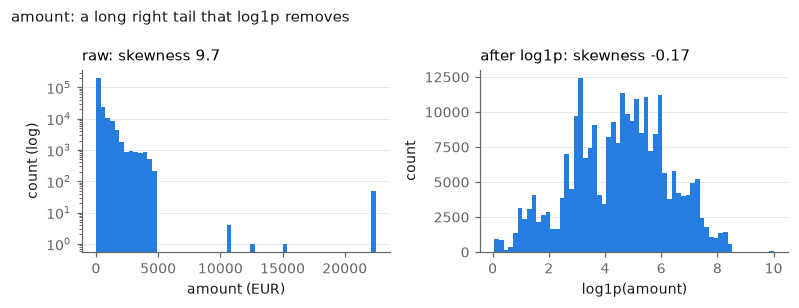

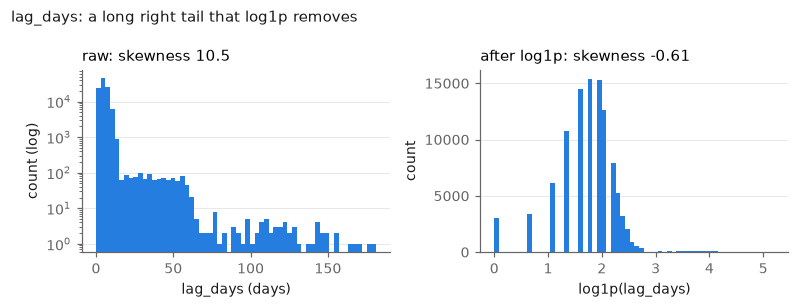

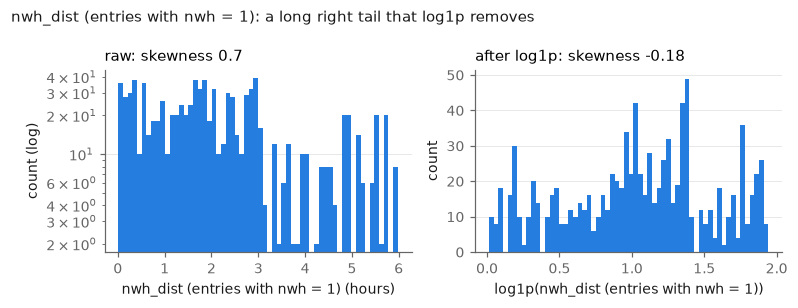

In [13]:
# cell_02_13
fig = fg.fig_numeric_distribution(lines["amount"], "amount", "EUR")
fg.save(fig, "fe_num_amount", FIG)
fig = fg.fig_numeric_distribution(ent["lag_days_raw"], "lag_days", "days")
fg.save(fig, "fe_num_lag_days", FIG)
fig = fg.fig_numeric_distribution(ent.loc[ent["nwh"] == 1, "nwh_dist_raw"], "nwh_dist (entries with nwh = 1)", "hours")
fg.save(fig, "fe_num_nwh_dist", FIG)

In [14]:
# cell_02_14
# min-max removes any preceding shift and positive rescaling, so the robust step (median / IQR)
# between log1p and min-max does not change the result (W6)
x = np.log1p(lines.loc[lines["fy"] == FY1, "amount"].to_numpy())
q1, q3 = np.percentile(x, [25, 75])
mm = lambda v: (v - v.min()) / (v.max() - v.min())
print("largest difference, robust + min-max vs min-max only:", np.abs(mm((x - np.median(x)) / (q3 - q1)) - mm(x)).max())

largest difference, robust + min-max vs min-max only: 1.1102230246251565e-16


**Result.**
- **Amount** and **lag_days** are non-negative with a long right tail (FY2023 skewness 10.3 and 11.6; rent EUR 22,500 against a median of about EUR 100; most entries recorded within a week, a few after months). log1p removes the tail (skewness about −0.2 and −0.5); log1p, not log, because 2.8 % of the entries have a lag of 0 days. Both are then min-max scaled to [0, 1] **per fiscal year** (D10), the range of the one-hot columns. The same transformation is used because both fields have the properties that call for it — it was not chosen by comparing results.
- The robust step in `Scaler` has no effect before min-max (difference at rounding level); the influence of large values is reduced by log1p alone (W6).
- Min-max per year depends on the year maximum: the lag maximum is 181 days in FY2023 and 64 in FY2024, so 30 days become 0.66 and 0.82. This is consistent inside each year, where the detectors are fitted.
- **nwh_dist** is 0 for most entries and bounded (at most about 6 hours): no long tail, so it is only divided by the year maximum, without log. (W7)

### Do the derived time features agree with the dataset's own time flags?

**Goal.** The dataset ships `promptly`, `weekend` and `nwh` as precomputed columns. If the fields derived from the raw timestamps reproduce them exactly, the model's time information comes from raw data, and `promptly` is shown to be a binning of `lag_days` (label-free evidence for D4).

In [15]:
# cell_02_15
bins = pd.cut(ent["lag_days_raw"], [-np.inf, 9, 29, np.inf], labels=[1, 2, 3]).astype(int)
print("promptly vs lag_days classes 0-9 / 10-29 / 30+, mismatches:", int((bins.to_numpy() != ent["promptly"].to_numpy()).sum()))
wk = np.select([ent["wday"] == 5, ent["wday"] == 6], [1, 2], 0)
print("weekend vs weekday of entered_date, mismatches:", int((wk != ent["weekend"].to_numpy()).sum()))
print("nwh_dist > 0 exactly when nwh = 1, mismatches:",
      int(((ent["nwh_dist_raw"].to_numpy() > 0) != (ent["nwh"].to_numpy() == 1)).sum()))
print("entry hours:", int(np.floor(ent["hour_t"]).min()), "to", int(np.floor(ent["hour_t"]).max()))

promptly vs lag_days classes 0-9 / 10-29 / 30+, mismatches: 0
weekend vs weekday of entered_date, mismatches: 0
nwh_dist > 0 exactly when nwh = 1, mismatches: 0
entry hours: 5 to 23


**Result.** 0 mismatches in all three: `promptly` is exactly the classes 0–9 / 10–29 / 30+ days of `lag_days`, `weekend` is the weekday of the entry date, and `nwh` is "outside 08:00–17:59". Entries are only made between 05:00 and 23:59, so the wrap-around that sin/cos encodes (23:00 next to 00:00) does not occur here.

## 6. Redundancy without labels: which candidate features are switched off (D4, D13)

**Goal.** Every fact should enter the distances once. A field B is redundant when every value of a field A determines exactly one value of B (functional dependency); then B adds no information and only gives the same fact more weight. The check uses no labels and the whole ledger. The booking pattern stands for the account + side block of the slots (one-to-one after D9). The dependent field is dropped, not the determining one, because the determining field holds all of its information and more. Cramér's V between the fields is shown to document redundancy only — it is **not** used to judge whether a field is useful.

functional dependencies (A determines B):
determines determined  values of A  values of B
   pattern    n_lines           29            3
   pattern   tax_rate           29            2
  lag_days   promptly          121            3
      hour        nwh           19            2
   weekday    weekend            7            3


WindowsPath('C:/MyWorks/Thesis/Jet/results/figures/fe_association_heatmap.png')

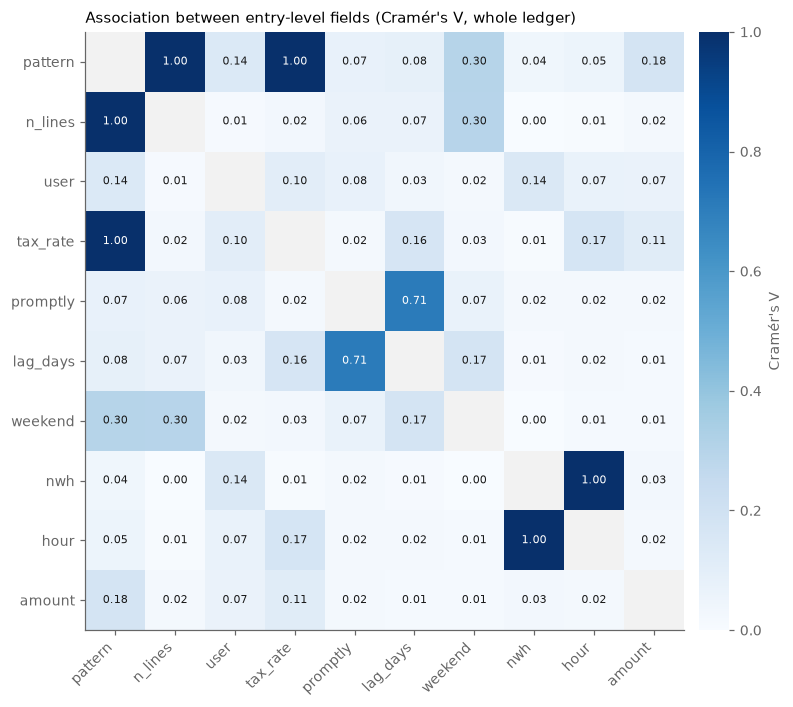

In [16]:
# cell_02_16
fd_cols = ["pattern", "n_lines", "user", "tax_rate", "promptly", "lag_days", "weekend", "nwh", "hour", "weekday"]
fd = fg.functional_dependencies(df, fd_cols)
print("functional dependencies (A determines B):")
print(fd.to_string(index=False))
red_cols = ["pattern", "n_lines", "user", "tax_rate", "promptly", "lag_days", "weekend", "nwh", "hour", "amount"]
assoc = fg.association_matrix(df, red_cols, numeric_bins={"lag_days": 10, "amount": 10})
fig = fg.fig_association_heatmap(assoc, "Association between entry-level fields (Cramér's V, whole ledger)")
fg.save(fig, "fe_association_heatmap", FIG)

In [17]:
# cell_02_17
# a low pairwise association does not mean "no signal": users per booking pattern
users_per_pattern = df.groupby("pattern")["user"].agg(entries="size", users="nunique")
single = users_per_pattern[users_per_pattern["users"] == 1]
print(f"Cramér's V user vs pattern: {assoc.loc['user', 'pattern']:.2f}; "
      f"patterns posted by one user only: {len(single)} of {len(users_per_pattern)} ({single['entries'].sum()} entries)")
print("share of weekend entries by number of lines:")
print(pd.crosstab(df["n_lines"], df["weekend"] > 0, normalize="index").round(3))

Cramér's V user vs pattern: 0.14; patterns posted by one user only: 21 of 29 (638 entries)
share of weekend entries by number of lines:
weekend  False  True 
n_lines              
2        0.696  0.304
3        0.997  0.003
4        1.000  0.000


**Result.**
- Dependencies found: booking pattern → `n_lines`, booking pattern → `tax_rate`, `lag_days` → `promptly`, and hour → `nwh`, weekday → `weekend`. Hence **`n_lines`, `tax_rate` and `promptly` are built but switched off** (D13, D4). Hour and weekday are not features in the main setting; if the sin/cos groups are switched on in an ablation, `nwh` and `weekend` become partly redundant.
- Section 8 confirms that nothing is lost: the number of distinct entry vectors is the same with and without the three dependent fields.
- `user` vs pattern has V = 0.14, yet 21 of the 29 patterns (the rare ones, 638 entries together) are posted by one user only, while the five large patterns are posted by all six users; the injected anomaly types M1–M6 lie largely in user × pattern (and user × time) combinations, which a pairwise measure cannot show. `weekend` vs `n_lines` (V = 0.30) reflects the generator: about 30 % of the two-line entries are posted on weekends, almost no three-line entries. (W12)

## 7. Descriptive views with labels — FY2023 only (D1, D4, D11)

**Goal.** Show how the anomaly rate relates to the item text, the delay, the time of day and the weekday. These views use labels, so they are drawn on **FY2023 only** (D6). They describe the data and support the decisions; they do not switch features on or off (section 6 does). Bars carry 95 % Wilson intervals, because several groups are small.

In [18]:
# cell_02_18
df1 = df[df["fy"] == FY1]
print(f"whole ledger {len(df):,} entries | FY2023 {len(df1):,} entries, {int(df1['label'].sum())} anomalies, "
      f"base rate {df1['label'].mean():.2%}")

whole ledger 102,429 entries | FY2023 51,064 entries, 423 anomalies, base rate 0.83%


### 7.1 Item text vs price (D1)

**Goal.** The free text `text` is not encoded (D1). Its main use in this ledger would be the item name. Two questions: does the anomaly rate per item follow the price, and is there any anomaly whose amount is unusual *for its item* (e.g. a cheap item booked at an expensive item's price) — the one case only the text could reveal?

,entries,anomalies,rate,ci_low,ci_high,median_amount
text,,,,,,
Gardening Gloves,5143,31,0.0060,0.0042,0.0085,7.32
Watering Can,5091,15,0.0029,0.0018,0.0049,58.91
Rake,4995,17,0.0034,0.0021,0.0054,94.61
Shovel,5213,19,0.0036,0.0023,0.0057,99.53
Garden Shears,4992,24,0.0048,0.0032,0.0071,106.39
Garden Hose,4941,17,0.0034,0.0021,0.0055,117.81
Hedge Trimmer,5119,42,0.0082,0.0061,0.0111,362.36
Leaf Blower,5178,39,0.0075,0.0055,0.0103,386.16
Wheelbarrow,4950,61,0.0123,0.0096,0.0158,472.99


FY2023 anomalies with an item text: 420, of which outside the normal amount range of their own item: 0


,normal_min,normal_max,anomalies,anomalies_outside_range
item,,,,
Lawn Mower,222.29,4445.84,155,0
Leaf Blower,77.23,1544.62,39,0
Gardening Gloves,1.48,29.51,31,0
Shovel,20.11,402.22,19,0
Hedge Trimmer,36.29,1449.42,42,0
Wheelbarrow,95.56,1911.14,61,0
Garden Shears,21.49,429.83,24,0
Rake,19.11,382.23,17,0
Watering Can,11.90,238.00,15,0


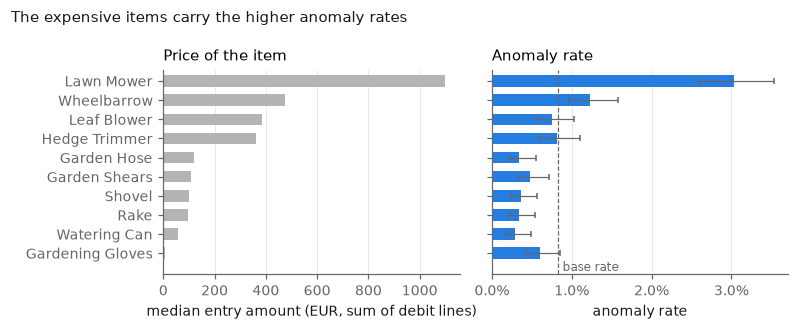

In [19]:
# cell_02_19
items = df["text"].value_counts().loc[lambda s: s > 1000].index.tolist()   # the 10 garden item names
fig, t_text = fg.fig_text_vs_price(df1, items)
fg.save(fig, "fe_d1_text_vs_price", FIG)
display(t_text.round(4))
chk = fg.item_amount_check(df1, items)
print(f"FY2023 anomalies with an item text: {chk['anomalies'].sum()}, "
      f"of which outside the normal amount range of their own item: {chk['anomalies_outside_range'].sum()}")
chk

**Result.** The expensive items carry the higher anomaly rates (Lawn Mower 3.0 %, Wheelbarrow 1.2 %), because the amount-based anomaly types use expensive items; the relation is not monotonic below that (Gardening Gloves, the cheapest item, 0.60 % against 0.29–0.48 % for mid-priced items). No anomaly has an amount outside the normal range of its own item, so the text adds nothing that the amount does not already carry in this ledger. Together with the other reasons of D1 (RQ2 fairness, comparability with prior work, synthetic texts unlike real ones) the text is not encoded. (W11)

### 7.2 Delay between document date and entry date (D4)

,entries,anomalies,rate,ci_low,ci_high
lag_bin,,,,,
0–4,18852,131,0.0069,0.0059,0.0082
5–9,28010,135,0.0048,0.0041,0.0057
10–14,3510,88,0.0251,0.0204,0.0308
15–19,82,4,0.0488,0.0191,0.1188
20–29,162,3,0.0185,0.0063,0.0530
30–44,196,36,0.1837,0.1357,0.2438
45–59,164,16,0.0976,0.0609,0.1526
60–89,32,3,0.0938,0.0324,0.2422
90+,56,7,0.1250,0.0619,0.2363


FY2023 anomalies by delay class and anomaly type (marking):


marking,1,2,3,4,5,6,7,8
lag_days,,,,,,,,
0-9,54,26,0,0,45,108,26,7
10-29,5,4,60,0,4,17,4,1
30+,1,0,0,60,1,0,0,0


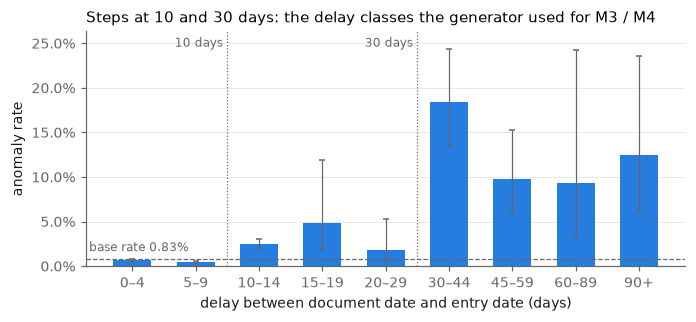

In [20]:
# cell_02_20
fig, t_lag = fg.fig_rate_by_lag(df1)
fg.save(fig, "fe_d4_rate_by_lag", FIG)
display(t_lag.round(4))
lag_class = pd.cut(df1["lag_days"], [-1, 9, 29, np.inf], labels=["0-9", "10-29", "30+"])
print("FY2023 anomalies by delay class and anomaly type (marking):")
pd.crosstab(lag_class[df1["label"] == 1], df1.loc[df1["label"] == 1, "marking"])

**Result.** The rate does not grow smoothly with the delay; it jumps at 10 and 30 days — exactly the edges of the dataset's delay classes, because the generator injected the delay anomalies by these classes (almost all anomalies with 10–29 days are M3, almost all with 30+ days are M4). The steps describe how the anomalies were generated, not real ledgers (L8). The model receives the delay in days, which contains these edges exactly, but not the class itself; a separate FY2023 check (ablation notebook) shows that the continuous delay ranks at least as well as the class with LOF. (W13, W14)

### 7.3 Time of day, distance from working hours, weekday (D11)

by hour
      entries  anomalies    rate  ci_low  ci_high
hour                                             
5          73          8  0.1096  0.0566   0.2016
6          86          9  0.1047  0.0560   0.1871
7          88         14  0.1591  0.0972   0.2495
8        5329         50  0.0094  0.0071   0.0123
9        5957         43  0.0072  0.0054   0.0097
10       5704         37  0.0065  0.0047   0.0089
11       5305         35  0.0066  0.0047   0.0092
12       5752         37  0.0064  0.0047   0.0089
13       5535         30  0.0054  0.0038   0.0077
14       5743         42  0.0073  0.0054   0.0099
15       5628         46  0.0082  0.0061   0.0109
16       5615         49  0.0087  0.0066   0.0115
17         25          0  0.0000  0.0000   0.1332
18         42          4  0.0952  0.0377   0.2207
19         42          3  0.0714  0.0246   0.1901
20         52          8  0.1538  0.0801   0.2752
21         34          4  0.1176  0.0467   0.2662
22         22          1  0.0455  0.0081  

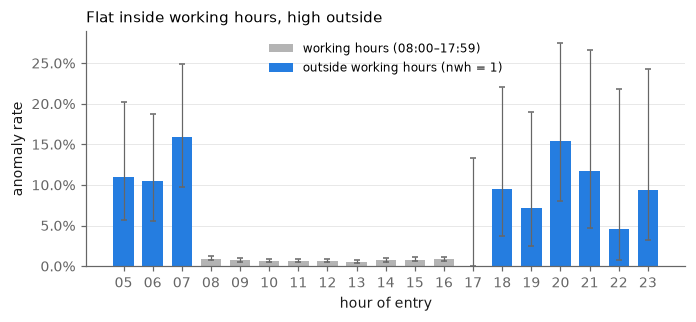

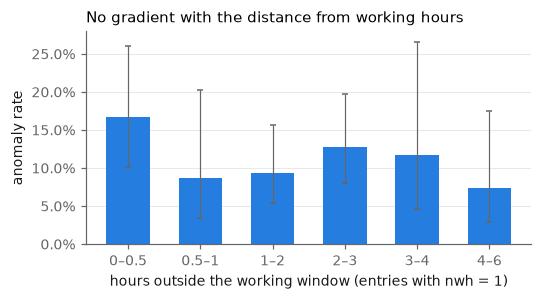

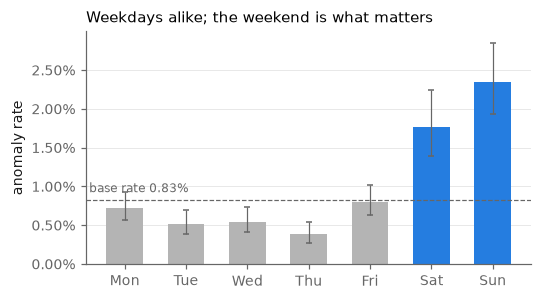

In [21]:
# cell_02_21
fig, t_hour = fg.fig_rate_by_hour(df1)
fg.save(fig, "fe_d11_rate_by_hour", FIG)
fig, t_dist = fg.fig_rate_by_distance(df1)
fg.save(fig, "fe_d11_rate_by_distance", FIG)
fig, t_wday = fg.fig_rate_by_weekday(df1)
fg.save(fig, "fe_d11_rate_by_weekday", FIG)
for name, t in [("by hour", t_hour), ("by distance outside working hours (nwh = 1)", t_dist), ("by weekday (0 = Mon)", t_wday)]:
    print(name); print(t.round(4).to_string()); print()

**Result.** Inside working hours (08–16) the rate is flat and low; outside (05–07, 18–23) it is high — a step that the `nwh` flag already captures. Within `nwh` = 1 there is **no gradient** with the distance from the working window (the closest bin is not lower than the far ones; all intervals overlap), so `nwh_dist` stays off. Weekdays are alike; Saturday and Sunday are higher and differ from each other, which the three-category `weekend` one-hot keeps; weekday sin/cos adds nothing beyond it. Hour 17 has 25 entries and no anomaly in FY2023 (the generator description starts non-working time at 17:00, the flag at 18:00 — L7).

## 8. Build the matrix with all candidate features

**Goal.** Build every candidate feature once (switched on or off later by group): 4 slots × (account one-hot + side one-hot + scaled amount), `user` once per entry, the time features, and the switched-off groups (`n_lines`, `tax_rate`, `promptly`, `nwh_dist`, hour / weekday sin/cos). Numeric scalers are fitted per fiscal year (D10). `build_onehot` repeats the sorting (D9) and the entry table of sections 3 and 5.

In [22]:
# cell_02_22
X, feature_info, params, sorted_lines, ent = fe.build_onehot(lines, meta)
print(X.shape, f"non-zeros: {X.nnz:,} ({X.nnz / len(meta):.1f} per entry)")
pd.Series([f["group"] for f in feature_info]).value_counts().rename("columns per group")

(102429, 140) non-zeros: 1,935,190 (18.9 per entry)


lines             126
calendar_flags      4
tax_rate            2
hour_cyc            2
wday_cyc            2
n_lines             1
promptly            1
lag_days            1
nwh_dist            1
Name: columns per group, dtype: int64

**Result.** 140 columns: `lines` 126 (4 × 30 slot columns + 6 users), `calendar_flags` 4 (weekend 3 + nwh), `lag_days` 1, and the switched-off groups `n_lines` 1, `tax_rate` 2, `promptly` 1, `nwh_dist` 1, `hour_cyc` 2, `wday_cyc` 2. Main setting = 126 + 4 + 1 = **131 columns**. About 19 of 140 values per entry are non-zero, so the matrix is stored sparse.

### Checks of the matrix

**Goal.** Code checks: the matrix has exactly the structure that was intended (they test the code, not the data). The data checks were done in section 5.

In [23]:
# cell_02_23
names = [f["name"] for f in feature_info]
col = {n: i for i, n in enumerate(names)}
pid = meta["posting_id"].to_numpy()
is1 = (meta["fy"] == FY1).to_numpy()


def colv(name):
    return np.asarray(X[:, col[name]].todense()).ravel()


assert np.isfinite(X.data).all()                                            # no NaN / inf
for s in range(1, fe.MAX_LINES + 1):
    a = [i for i, f in enumerate(feature_info) if f["slot"] == s and f["name"].startswith(f"s{s}_acct_")]
    c = [i for i, f in enumerate(feature_info) if f["slot"] == s and f["name"].startswith(f"s{s}_cd_")]
    assert (np.asarray(X[:, a].sum(axis=1)).ravel() == 1).all()            # (a) one account category per slot
    assert (np.asarray(X[:, c].sum(axis=1)).ravel() == 1).all()            #     one side category per slot
    filled = colv(f"s{s}_acct_PAD") == 0
    assert (filled == (meta["n_lines"].to_numpy() >= s)).all()             # (b) padding matches the number of lines
    amt = colv(f"s{s}_amount")                                             # (c) scaled amounts of real lines
    ranges = {fy: amt[filled & (meta["fy"] == fy).to_numpy()] for fy in (FY1, FY2)}
    print(f"s{s}_amount  " + "   ".join(f"FY{fy} [{v.min():.3f}, {v.max():.3f}]" if len(v) else f"FY{fy} (no lines)"
                                         for fy, v in ranges.items()))
    assert amt[filled].min() >= -1e-9 and amt[filled].max() <= 1 + 1e-9
for prefix in ["user_", "weekend_"]:
    idx = [i for i, n in enumerate(names) if n.startswith(prefix)]
    assert (np.asarray(X[:, idx].sum(axis=1)).ravel() == 1).all()          # one user / one weekend category per row
for nm in ["lag_days", "nwh_dist"]:
    v = colv(nm)
    assert v.min() >= -1e-9 and v.max() <= 1 + 1e-9
# row alignment: row i of X must be entry i of meta
assert pid[colv("s4_acct_PAD") == 0].tolist() == ["p_2"]                   # the only 4-line entry
assert colv("s1_acct_1576")[np.flatnonzero(pid == "a_1")[0]] == 1           # a_1 starts with D 1576 (D9)
print("all checks passed")

s1_amount  FY2023 [0.016, 1.000]   FY2024 [0.012, 1.000]
s2_amount  FY2023 [0.000, 1.000]   FY2024 [0.000, 1.000]
s3_amount  FY2023 [0.021, 0.960]   FY2024 [0.031, 0.840]
s4_amount  FY2023 (no lines)   FY2024 [0.748, 0.748]
all checks passed


**Result.** No missing values; every slot has exactly one account and one side category; padding matches the number of lines; all scaled values lie in [0, 1] in both years; the rows are aligned with `meta` (`p_2` is the only row with slot 4 filled, `a_1` starts with account 1576). An amount of 0 means PAD *and* the smallest amount of the year (min-max maps the year minimum to 0); the PAD columns keep the two apart.

### Identical vectors and the LOF neighbourhood (D15)

**Goal.** Many entries can have exactly the same vector. For LOF, a point with k or more identical neighbours has a k-distance of 0 and an unstable density (Campos et al., 2016), so k must be larger than the largest group of identical vectors. The check is label-free, so it runs for both years and for every feature setting used in the experiments (`fe.ABLATIONS`).

distinct FY2023 vectors, main + n_lines + tax_rate + promptly: 24207


columns  distinct vectors  entries sharing their vector  largest group  LOF k at least
setting       fy                                                                                          
main          2023      131             24207                         36137             36              37
              2024      131             24278                         36472             36              37
main+nwh_dist 2023      132             24210                         36131             36              37
              2024      132             24283                         36462             36              37
main+hour_cyc 2023      133             50837                           283             12              13
              2024      133             51120                           312             12              13
main+wday_cyc 2023      133             34358                         25794             18              19
              2024      133             34562                         25933             18              19
main+promptly 2023      132             24207                         36137             36              37
              2024      132             24278                         36472             36              37
no_time       2023      126              3547                         50738            187             188
              2024      126              3732                         50890            174             175

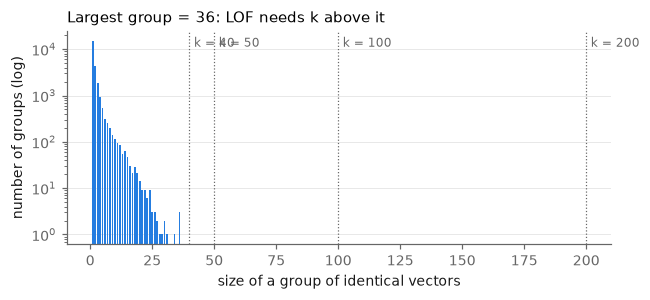

In [24]:
# cell_02_24
rows = []
for name, groups in fe.ABLATIONS.items():
    Xs, _ = fe.select_columns(X, feature_info, groups)
    for fy in (FY1, FY2):
        D = Xs[(meta["fy"] == fy).to_numpy()].toarray()
        _, inv, counts = np.unique(D, axis=0, return_inverse=True, return_counts=True)
        rows.append({"setting": name, "fy": fy, "columns": D.shape[1], "distinct vectors": len(counts),
                     "entries sharing their vector": int((counts[inv.ravel()] > 1).sum()),
                     "largest group": int(counts.max()), "LOF k at least": int(counts.max()) + 1})
dups = pd.DataFrame(rows).set_index(["setting", "fy"])
# the three dependent fields of section 6 add no information: same number of distinct vectors
Xa, _ = fe.select_columns(X, feature_info, {**fe.FEATURE_GROUPS_MAIN, "n_lines": True, "tax_rate": True, "promptly": True})
print("distinct FY2023 vectors, main + n_lines + tax_rate + promptly:", len(np.unique(Xa[is1].toarray(), axis=0)))
X_main_fy1, _ = fe.select_columns(X, feature_info, fe.FEATURE_GROUPS_MAIN)
fig, _ = fg.fig_duplicate_groups(X_main_fy1[is1].toarray())
fg.save(fig, "fe_d15_duplicate_groups", FIG)
dups

**Result.** In the main setting, 36,137 of the 51,064 FY2023 entries (71 %) share their vector with at least one other entry; the largest group has 36 members in both years (recurring payroll postings), so LOF needs k ≥ 37 — the grid 50 / 100 / 200 and the edge step k = 40 that notebook 03 tests next to the best grid value are all above it (D15). The constraint depends on the setting: without time features the largest group has 187 members (k ≥ 188); with the hour on a circle (`hour_cyc`) almost every entry is unique (largest group 12), while `nwh_dist` changes almost nothing (it is 0 for 99 % of the entries). Adding the three dependent fields back leaves the number of distinct vectors unchanged (24,207), which confirms that switching them off loses nothing. (W15, W12)

## 9. Save once, choose the features per run

**Goal.** Store all 140 columns once, with the information later notebooks need to use the file safely: column names and groups, fitted parameters (category lists, scaler values per year), the encoding version and the row order (`posting_id` of every row).

In [25]:
# cell_02_25
DERIVED.mkdir(parents=True, exist_ok=True)
fe.save_encoding(X, feature_info, params, DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json",
                 posting_ids=meta["posting_id"])
print("saved:", DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json", f"(encoding {fe.ENCODING_VERSION})")

saved: C:\MyWorks\Thesis\Jet\data\derived\X_onehot.npz C:\MyWorks\Thesis\Jet\data\derived\onehot_features.json (encoding v3)


**Result.** `X_onehot.npz` (sparse, float32) and `onehot_features.json`. `load_encoding` refuses a file written by another encoding version, and — when `meta` is passed — a file whose row order differs from `meta.parquet`, so a stale file cannot be run and labelled with a newer version in `results/runs.csv`.

**How later notebooks use it** (notebooks 03–10): load once with the row check, choose a feature setting from `fe.ABLATIONS`, and fit per fiscal year (D6). Write `fe.groups_label(groups)` into the `feature_groups` column of `results/runs.csv`.

In [26]:
# cell_02_26
X, feature_info, params = fe.load_encoding(DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json", meta=meta)

for name, groups in fe.ABLATIONS.items():
    Xs, _ = fe.select_columns(X, feature_info, groups)
    print(f"{name:15s} {fe.groups_label(groups):70s} {Xs.shape[1]:4d} columns, "
          f"LOF k >= {dups.loc[(name, FY1), 'LOF k at least']}")

X_main, names_main = fe.select_columns(X, feature_info, fe.ABLATIONS["main"])
assert X_main.shape[1] == 131                          # main setting, encoding v3
X_main_fy1 = X_main[(meta["fy"] == FY1).to_numpy()]    # detectors are fitted per fiscal year (D6)
X_main_fy2 = X_main[(meta["fy"] == FY2).to_numpy()]
print("FY2023:", X_main_fy1.shape, "| FY2024:", X_main_fy2.shape)

main            lines+calendar_flags+lag_days@v3                                        131 columns, LOF k >= 37
main+nwh_dist   lines+calendar_flags+lag_days+nwh_dist@v3                               132 columns, LOF k >= 37
main+hour_cyc   lines+calendar_flags+lag_days+hour_cyc@v3                               133 columns, LOF k >= 13
main+wday_cyc   lines+calendar_flags+lag_days+wday_cyc@v3                               133 columns, LOF k >= 19
main+promptly   lines+calendar_flags+lag_days+promptly@v3                               132 columns, LOF k >= 37
no_time         lines@v3                                                                126 columns, LOF k >= 188
FY2023: (51064, 131) | FY2024: (51365, 131)


**Result.** Main setting `lines+calendar_flags+lag_days@v3` = 131 columns; ablations add one group each (`+nwh_dist`, `+hour_cyc`, `+wday_cyc`, `+promptly`) or remove all time features (`no_time`, 126 columns, needs LOF k ≥ 188).

## Notes for the thesis
Text drafts with their reasoning are in `thesis_writing_snippets.md`:
- Ch. 3, entry level vs line level and the tax-rate caveat — **W1**; terminology debit/credit sequence vs booking pattern — **W2**; whole-ledger tables vs FY1-only label views — **W3**.
- Line order D9 (what the 50 % means, slot alignment, cost) — **W9**.
- Categories, new values per year, dimension on real ledgers — **W8**.
- Numeric features and scaling — **W7**, robust step — **W6**; entry amount = sum of debit lines — **W10**.
- Redundancy check — **W12**; free text D1 — **W11**; delay steps from the generator — **W13**; delay in days vs class — **W14**; identical vectors and LOF k — **W15**.
- Ch. 5: the four-line entry `p_2` — **W5** (check its rank in notebook 03 with this encoding).